# pyphysicell MVP — a PhysiCell project, in a notebook

This notebook runs **PhysiCell's own `rules_sample` project**, unmodified, from Python.
No C++ project is compiled, no executable is built, no output folder is parsed.

The architecture: **Python owns the model, the state and the time loop; C++ owns the
inner loops** (diffusion, mechanics, secretion), parallelised with OpenMP where the
toolchain has it and `std::thread` otherwise.

What to look for:
1. the project's own XML and rules CSV read into a model object
2. checks that cost milliseconds and say something true about the model
3. the rule response curves — a pure function, no simulation
4. a run, with the population curve recorded **during** the run
5. state you can read and change at any point

In [1]:
import numpy as np, matplotlib.pyplot as plt
import pyphysicell as pc
from pyphysicell import viz
print('kernels:', pc.BACKEND, '|', pc.MAX_THREADS, 'threads')

kernels: std::thread | 2 threads


## 1. Load their project

In [2]:
PROJECT = '../../PhysiCell/sample_projects/rules_sample'
model = pc.load(PROJECT)
print(model.summary())

model 'rules_sample'  [877007e601e3]
  domain     50 x 50 x 1 voxels, dx=20 um, 2D
  time       dt_diff=0.01 dt_mech=0.1 dt_pheno=6  max_time=7200 min
  substrates oxygen, apoptotic debris, necrotic debris, pro-inflammatory factor, anti-inflammatory factor
  cell types malignant epithelial cell, M0 macrophage, M1 macrophage, M2 macrophage, effector T cell, exhausted T cell
  rules      27
  initial    1300 cells


## 2. Checks that need no simulation

`check()` is dimensional analysis of the model as written. It takes milliseconds and it
finds real things in a project that ships with PhysiCell.

In [3]:
print(pc.check(model))

check: 'rules_sample' [877007e601e3]
  [ok      ] oxygen                     L=sqrt(D/lambda)=  1000.0 um =  50.0 dx
  [note] apoptotic debris           D=1, lambda=0; no decay: no steady length scale, spreads ~54 um per day
  [note] necrotic debris            D=1, lambda=0; no decay: no steady length scale, spreads ~54 um per day
  [marginal] pro-inflammatory factor    L=sqrt(D/lambda)=   100.0 um =   5.0 dx
  [marginal] anti-inflammatory factor   L=sqrt(D/lambda)=   100.0 um =   5.0 dx
  [info    ] malignant epithelial cell  cycle mean duration 513.1 h (from the phase graph, no simulation)
  [info    ] M0 macrophage              does not cycle on its own (rate 0; a rule may drive it)
  [info    ] M1 macrophage              does not cycle on its own (rate 0; a rule may drive it)
  [info    ] M2 macrophage              does not cycle on its own (rate 0; a rule may drive it)
  [info    ] effector T cell            does not cycle on its own (rate 0; a rule may drive it)
  [info    ] exha

`inspect()` reports how much of the project this MVP can actually run, and names what
it cannot. Nothing is silently ignored.

In [4]:
print(pc.inspect(model))

inspect: 'rules_sample' [877007e601e3]
model 'rules_sample'  [877007e601e3]
  domain     50 x 50 x 1 voxels, dx=20 um, 2D
  time       dt_diff=0.01 dt_mech=0.1 dt_pheno=6  max_time=7200 min
  substrates oxygen, apoptotic debris, necrotic debris, pro-inflammatory factor, anti-inflammatory factor
  cell types malignant epithelial cell, M0 macrophage, M1 macrophage, M2 macrophage, effector T cell, exhausted T cell
  rules      27
  initial    1300 cells

  cycle models      Flow cytometry model (separated), live
  signals available 39
  behaviors available 106
  rules             27 total, 27 runnable, 0 skipped
  behaviors driven by rules: 21
  tier: A (runs as-is)


## 3. The grammar, and what a rule actually does

Signals and behaviors are derived from this model's substrates and cell types, so they
can be listed and searched. A rule is a pure function of its signal: plotting it costs
nothing and is the closest thing here to a band structure.

In [5]:
d = pc.Dictionary(model)
print('signals  :', d.signals[:8], '...')
print('behaviors:', d.behaviors[:6], '...')
print('search "debris":', d.search('debris')[:6])

signals  : ['oxygen', 'apoptotic debris', 'necrotic debris', 'pro-inflammatory factor', 'anti-inflammatory factor', 'intracellular oxygen', 'intracellular apoptotic debris', 'intracellular necrotic debris'] ...
behaviors: ['phagocytose apoptotic cell', 'phagocytose necrotic cell', 'phagocytose other dead cell', 'phagocytose dead cell', 'attack damage rate', 'attack duration'] ...
search "debris": ['apoptotic debris', 'necrotic debris', 'intracellular apoptotic debris', 'intracellular necrotic debris', 'apoptotic debris gradient', 'necrotic debris gradient']


In malignant epithelial cell cells, oxygen decreases necrosis towards 0 with half-max 3.75 and Hill power 8.
In malignant epithelial cell cells, oxygen increases cycle entry towards 0.003333 with half-max 21.5 and Hill power 4.
In malignant epithelial cell cells, pressure decreases cycle entry towards 0 with half-max 1 and Hill power 4.


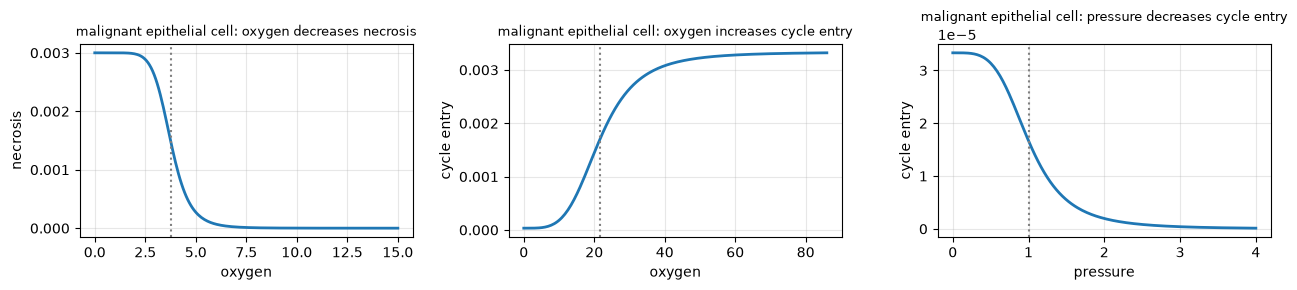

In [6]:
rules = [r for r in model.rules if r.cell_type == 'malignant epithelial cell']
fig, axes = plt.subplots(1, len(rules[:3]), figsize=(13, 3))
for ax, r in zip(axes, rules[:3]):
    viz.plot_rule(r, d.base_behavior(r.cell_type, r.behavior), ax=ax)
    print(r.english())
plt.tight_layout()

## 4. Run it

In [7]:
sim = pc.Simulation(model, seed=0)
print(sim)
print(sim.ruleset.report())

<Simulation 'rules_sample' t=0.0 min cells=1300 backend=std::thread:2>
ruleset: 27 rules, 21 behaviors applied, 0 rules skipped


<Axes: title={'center': 't = 0 min   n = 1300'}, xlabel='x [um]', ylabel='y [um]'>

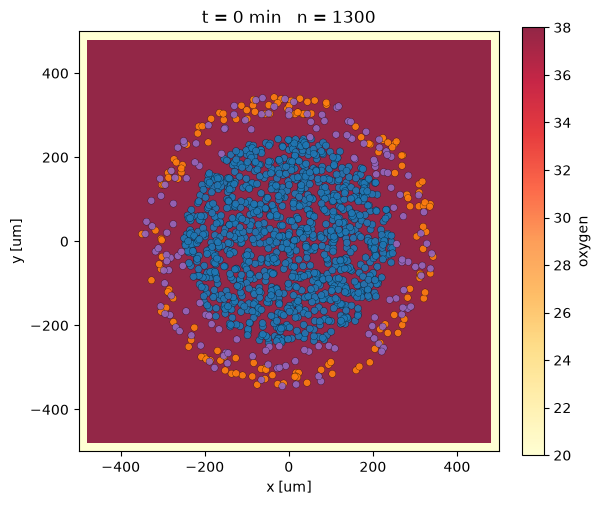

In [8]:
fig, ax = plt.subplots(figsize=(6, 6))
viz.plot_cells(sim, substrate='oxygen', ax=ax)

In [9]:
scalars = sim.run(until=720, record_every=30, progress=True)   # 12 simulated hours
print(f'wall time {sim.wall_time:.1f} s')

  t=     0.0 min  cells=  1300


  t=    30.0 min  cells=  1300


  t=    60.0 min  cells=  1300


  t=    90.0 min  cells=  1300


  t=   120.0 min  cells=  1300


...

  t=   600.0 min  cells=  1289


  t=   630.0 min  cells=  1288


  t=   660.0 min  cells=  1283


  t=   690.0 min  cells=  1280


wall time 26.5 s


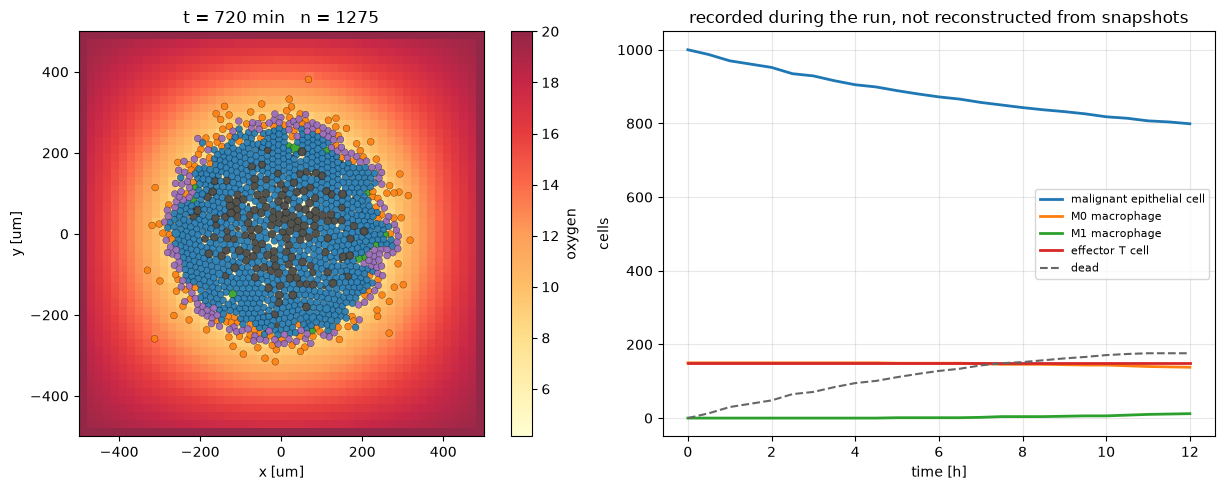

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
viz.plot_cells(sim, substrate='oxygen', ax=axes[0])
viz.plot_populations(scalars, ax=axes[1])
axes[1].set_title('recorded during the run, not reconstructed from snapshots')
plt.tight_layout()

The population curve above is a tier-1 artifact: a few hundred bytes, written while the
simulation runs. PhysiCell Studio builds the same plot by loading every `output*.xml`
in the folder through pyMCDS after the fact.

In [11]:
df = scalars.to_dataframe()
df.tail()

,time,dead,births,deaths,n_malignant epithelial cell,n_M0 macrophage,n_M1 macrophage,n_M2 macrophage,n_effector T cell,n_exhausted T cell,mean_oxygen,mean_apoptotic debris,mean_necrotic debris,mean_pro-inflammatory factor,mean_anti-inflammatory factor
20,600.0,171,0,189,818,144,6,0,150,0,12.896593,0.001756,0.066689,0.036842,0.0
21,630.0,174,0,194,814,142,8,0,150,0,12.914592,0.001901,0.069694,0.047347,0.0
22,660.0,176,0,202,807,140,10,0,150,0,12.933282,0.002015,0.072614,0.056075,0.0
23,690.0,176,0,206,804,139,11,0,150,0,12.941660,0.002068,0.075639,0.061613,0.0
24,720.0,176,0,212,799,138,12,0,150,0,12.957217,0.002106,0.078319,0.067364,0.0


## 5. The state is right here

Cells and fields are NumPy arrays owned by Python. Read them, change them, carry on.

In [12]:
cells = sim.dataframe()
print(cells.groupby('cell_type').agg(n=('ID', 'size'), mean_pressure=('pressure', 'mean')))
o2 = sim.cells.sampled[:sim.cells.n, 0]
print(f'{(o2 < 10).mean():.1%} of cells are below 10 mmHg oxygen at t={sim.t:.0f} min')

                             n  mean_pressure
cell_type                                    
M0 macrophage              138       2.139432
M1 macrophage               12       5.804453
effector T cell            150       2.779722
malignant epithelial cell  975       3.230219
97.4% of cells are below 10 mmHg oxygen at t=720 min


<Axes: xlabel='time [h]', ylabel='cells'>

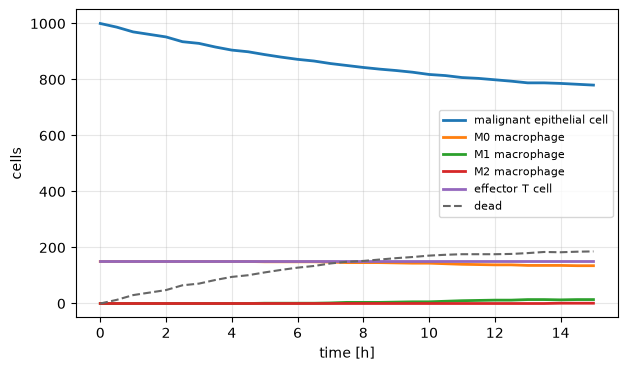

In [13]:
# intervene mid-run: flood the domain with oxygen and keep going
sim.microenvironment.density[..., 0] = 38.0
sim.run(until=sim.t + 180, record_every=30)
viz.plot_populations(sim.scalars)

## 6. Re-colour without re-running

Colouring is a Python call on stored state. In PhysiCell it is a C++ function pointer
bound in `main.cpp`, so changing it means editing C++, recompiling and running again.

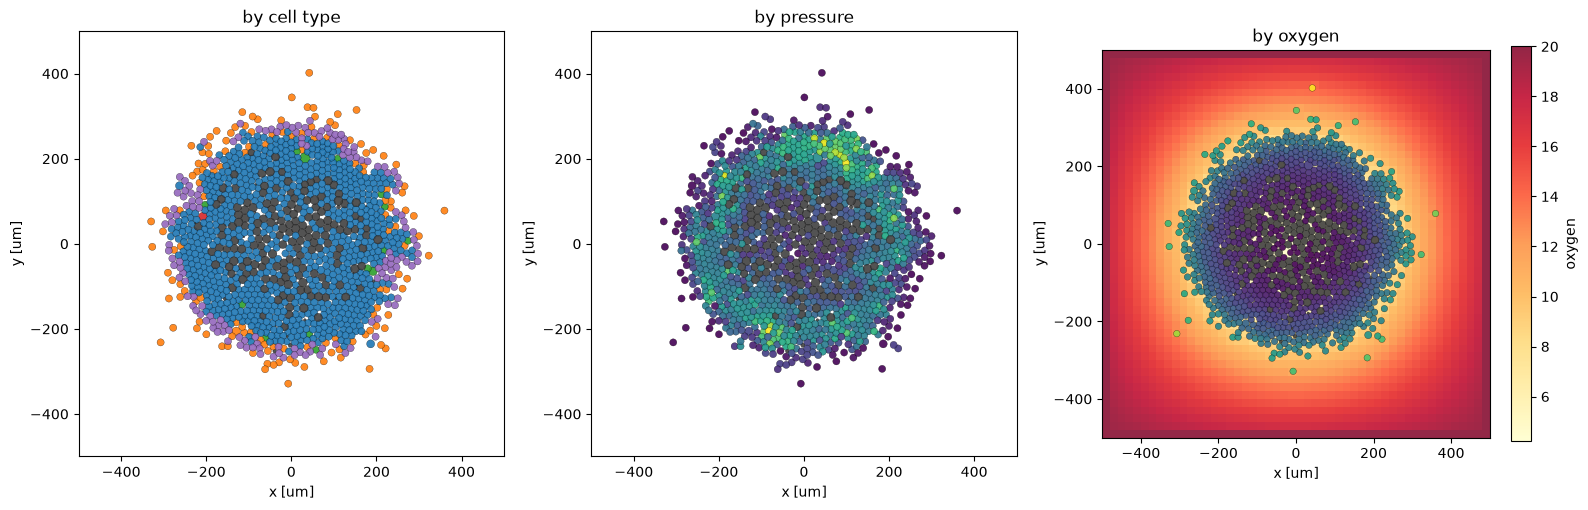

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
viz.plot_cells(sim, color_by='cell_type', ax=axes[0]); axes[0].set_title('by cell type')
viz.plot_cells(sim, color_by='pressure', ax=axes[1]); axes[1].set_title('by pressure')
viz.plot_cells(sim, color_by='oxygen', substrate='oxygen', ax=axes[2]); axes[2].set_title('by oxygen')
plt.tight_layout()